<h1>Muistiinpanot 02: Menetelmät 1</h1>

<h3>Yksinkertainen neuroverkko</h3>

<div> 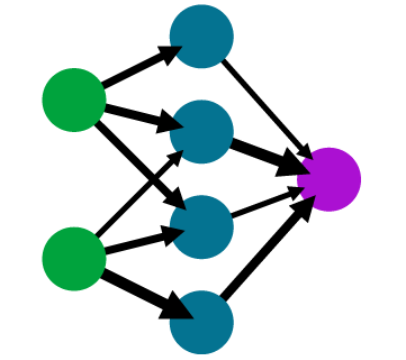 </div>

<b>Kuinka monta koulutettavaa mallia tällä neuroverkolla olisi?</b><br/>
$4*(2+1)+(4+1) = 12 + 5 = 17$


<h3>Yksittäinen neuroni</h3>

<div> 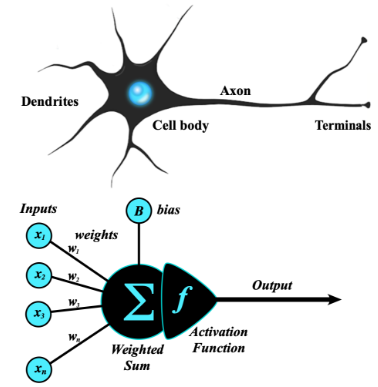 </div>

Yksittäinen neuroni neuroverkossa tekee kaikissa kaksi täysin samaa asiaa. Se laskee painokertoinet (weights) ja ns. ennakkoasennetta eli biasia. Sen jälkeen se syöttää laskutoimituksen aktivaatiofunktiolle ja sen palauttama arvo välitetään eteenpäin.

<h4>Aktivaatiofunktiot</h4>

<b>Sigmoid aktivaatiofunktio</b>

- Todella hyvä funktio, jos haluaa selvittää binääristäongelmaa.
    - esim. funktio antaa arvoksi 0.84 -> Tämä tarkoittaa että ennuste kuuluisi 84% luokkaan 1 ja 16% luokkaan 0.
 
<div> 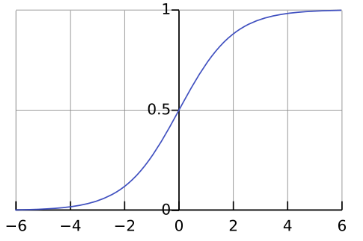 </div>

$Sigmoid aktivaatiofunktio = \frac{1}{1+e^{-z}}$

<b>Softmax</b>

- Loistava jos luokitellaan enempään kuin kaksi luokkaa.

<b>ReLU (Rectified Linear Unit)</b>
<div> 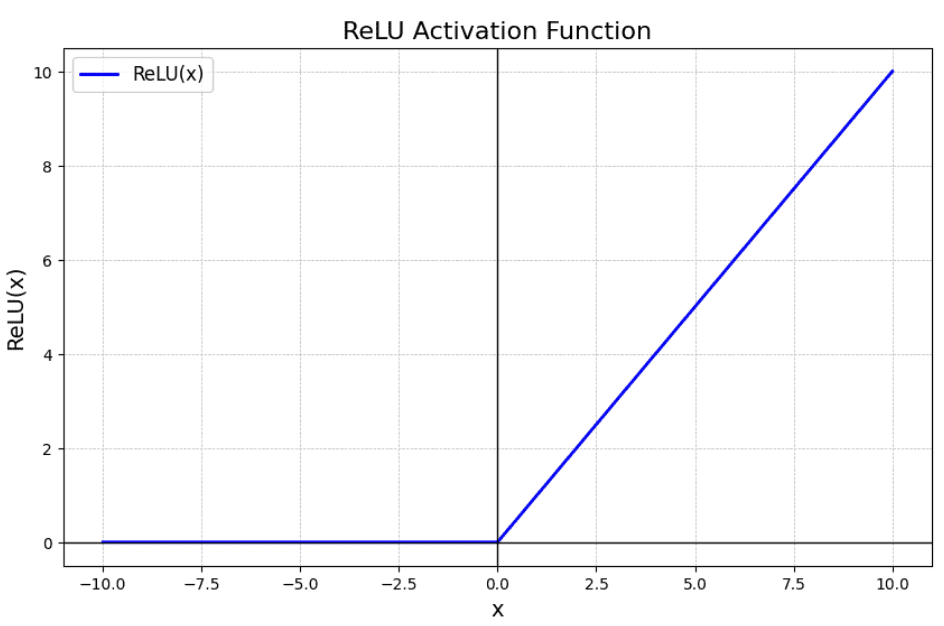 </div>

<h3>Termistöä</h3>

<b>Hyperparametrit</b><br/>

- Ohjelmoija valitsee nämä etukäteen.
- Eivät muutu koulutuken aikana.
    - Piilokerrosten lukumäärä.
    - Neuronien lukumäärä.
- Ei ole selvää teoriaa mitä lukuja syöttää, eli joutuu kokeilemaan. (On jotain suuntaviivoja kylläkin)

<b>Koulutettavat parametrit</b><br/>

- Lukuarvot alustetaan automaattisesti. (yleensä satunnaisia)
- Muuttuvat neuroverkon koulutuksen aikana
    - Neuronin painoarvot tai vakiotermit

<h2>Koodiesimerkki</h2>

In [9]:
import keras

from keras.models import Sequential
from keras.layers import Input, Dense, Flatten
from keras.datasets import mnist
from keras.utils import to_categorical

ModuleNotFoundError: No module named 'keras'

In [10]:
#x_train on tensori (60000, 28, 28)
#y_tain on vektori (60000, ), joka on kokonaislukuja 0-9, vastemuuttuja-arvot joita halutaan ennustaa.

(x_train, y_train), (x_test, y_test) = mnist.load_data()


NameError: name 'mnist' is not defined

In [11]:
# kaikki luvut 0-255, 0 musta 255 valkoinen
# operoidaan mieluitein, niin että kaikki luvut ovat ~1 suuruisia laskennan tasapainottamiseksi.
x_train = x_train / 255.0
x_test = x_test / 255.0

#esim 5. muutetaan listaksi jossa on kymmenen alkiota.
# 5 -> [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
#one-hot encoding!!!
#ennusteet softmaxilla ovat luokkaa [0.11, 0.123, 0.01, 0.09, ...]
#tämä ei ole enään pakollinen vaihe, voi syöttää malille ja sanoa et kato ite? :D
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

NameError: name 'x_train' is not defined

In [12]:
# sequal -tyypin olio, jolle kerrotaan sen muoto
# annetaan halutut kerrokset listana
# INPUT = minkä kokoisia nämä kuvat ovat
# FLATTEN() = Muuttaa 2D listan suoraksi listaksi. (Voi tehdä muulla tavalla, esim itse käyttämällä  esim. x_train.reshape() )
# 1. DENSE() = Ensimmäinen piilokerros jossa 128 neuronia, jokainen samassa kerroksessa oleva neuroni pitää sisällään saman aktivaatiofunktion!!
# 2. DENSE() = Outputti, aktivaatiofunktio softmax <3

#MALLI 
# Input kerros 28*28 = 784 neuronia
# Hidden kerros 128 neuronia
# Output kerros 10 mahdollista ennustetta, 0-9 :)

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
    ])

NameError: name 'Sequential' is not defined

In [13]:
# optimizer= mitä optimizer algoritmia haluaa käyttää, parhaimmat rmsprop ja adam. Ei tarvvii mittää tietää käytä muita ku muutki.
# loss = Kustannusfunktio, joka määrittää eriarvoisuuden miten täsmällisesti lasketaan huonousluku, mitä suurempi kustannus sitä huonompi.
# metrics = jos haluan seurata kustannusarvon lisäksi muita arvoja kuten accuracy, precision, recall etc.

model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

NameError: name 'model' is not defined

In [20]:
# opetusjoukon selittävät muuttujat, oikeat tunnisteen ja kerrotaan kuinka pitkää haluamme kouluttaa ja eräkoko.
# epoch = kuinka monta kertaa opetusjoukko käydäänläpi.
# batch = kuinka monen erissä katsotaan opetusjoukkoa, esimerkissä 32 arvoa otetaan käsittelyyn ja katsotaan sen keskiarvo.
# batch=32, joku maaginen luku jota jokainen AI meastro käyttää? (Hyvä valinta on 2 potenssiarvo)

model.fit(x_train, y_train, epochs=5, batch_size=32) #jos fit komentoa ajaa uudestaan monta kertaa se jatkaa siitä mihin on viimeksi jäänyt!!!!!
#LISÄÄ VALIDATION SPLIT 

NameError: name 'model' is not defined

In [15]:
# Evaluoidaan malli. On olemassa myös predict komento, jolla ennustetaan arvoja.
# erillinen evaluate jos sille syöttää testijoukon, se palauttaa kaksi asiaa: kustannusfunktion(ei kerro mitään) ja listana muut pyydetyt metriikat.

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_acc}')

NameError: name 'model' is not defined

In [18]:
# hyödyllinen, näyttää taulukkomuodossa mallin kerrokset ja näyttää minkä muotoinen tensori tulee ulos 
# jokaisesta kerroksesta ja monta koulutettaavaa parametria siinä on.

# ja kuinka monta koulutettavaa kerrosta.
# 1. piilokerros, siinä on 128 neuronia, ja koulutettavia parametrejä 100, 480 (128 * 784 + 128) (edeltävä kerros * nykyinenkerros + bias)
# 2. output, 
model.summary()

NameError: name 'model' is not defined

<b>MALLIN VALIDOINTI</b>
  
- jaetaan data kolmeen osaan: koulutus, validointi ja testi
    - KOULUTUS (TRAIN): koulutetaan epoceilla ja muilla
    - VALIDOINTI (VAL): täältä tulee riippumatonta tietoa suorituskykyä, jota voi kokeilla 5 eri mallilla
    - TESTI (TEST): pidetään ulkona ihan loppuun asti